In [7]:
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [25]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'
RESULTS = 'average_10_experiments_20211124-202913.csv'
parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
velocity = float(parser.get("BUS", "VELOCITY"))

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize
         }

In [27]:
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()

ValueError: Could not interpret value `episode` for parameter `x`

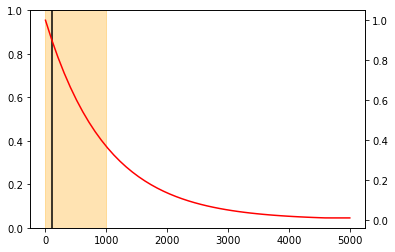

In [28]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
plt.axvline(min_experience, color='black', label='training start')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

plt.title('Experiment with Penalty = 15, soft update with tau=0.001 at every step')
fig.patch.set_facecolor('white')
ax2.set_ylabel('service level / eps')
fig.legend(bbox_to_anchor=(1.04,0.5), loc="center left")
fig.show()

In [17]:
BENCHMARK = '100_episodes_benchmark_20211108-152540.csv'
ROLLING = 10

<AxesSubplot:xlabel='episode', ylabel='service_level_MA'>

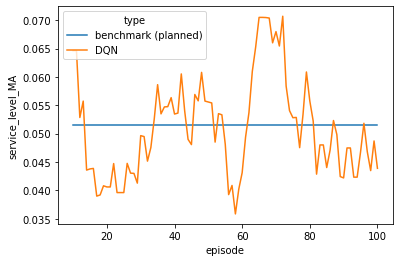

In [18]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK))
# noinspection JupyterPackage
benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(data=benchmark_results, x='episode', y='service_level_MA', hue='type')

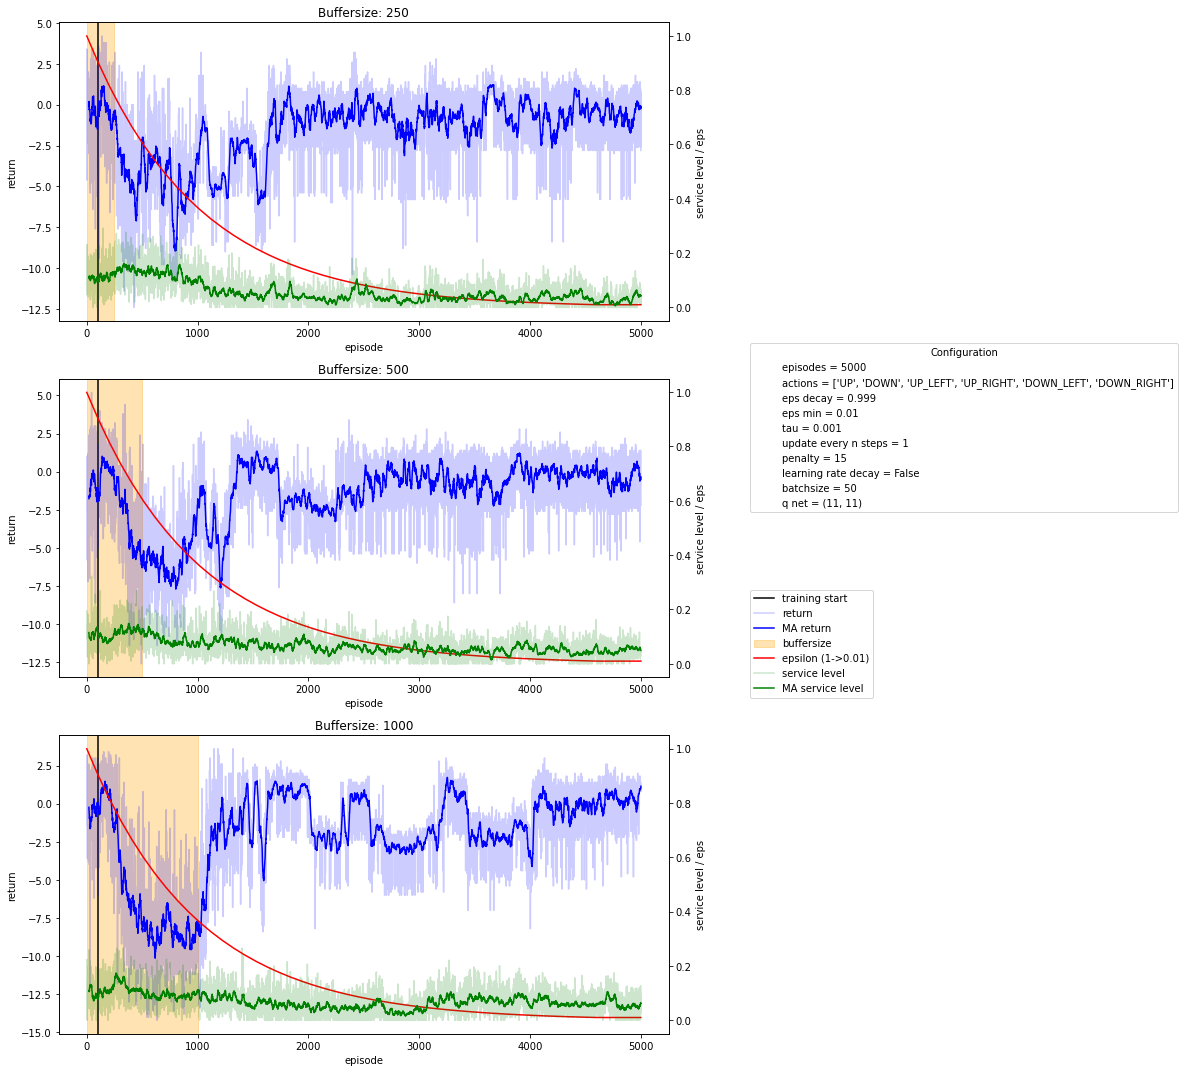

In [50]:
import matplotlib.patches as mpatches

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

RESULTS = 'search_buffersize_experiments_averaged_5_20211114-165302.csv'
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

if 'buffersize' in list(results):
    fig, ax = plt.subplots(results['buffersize'].nunique(), figsize=(10,15))
    for i, (name, group) in enumerate(results.groupby('buffersize')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Buffersize: {name}')

if 'action_space' in list(results):
    experiments = results['action_space'].nunique()
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('action_space')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Action space: {name}')
        
if 'lr_decay' in list(results):
    experiments = results['lr_decay'].nunique()
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('lr_decay')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()
        
        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Decaying Learning Rate: {name}')

handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.4), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.6), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()